# G2L-Theorie mit NN-Emulator

Pipeline: NN (Parameter, $z$ -> $P_{gm}(k, z)$) -> Limber $C_{\kappa g}(\ell)$ -> Hankel $\gamma_t(\theta)$.

- Rechnung in `g2l_nn.py`; Emulator: `NN_GM/gm_emulator.npz` (erzeugt mit `export_gm_emulator.py` aus dem trainierten Keras-Modell in `NN_GM/`).
- **Variante B (NN mit $z$-Eingang)** wird automatisch genutzt, sobald `NN_GM/gm_emulator.npz` existiert. Sonst faellt `g2l_nn.py` auf das alte $z=0$-NN mit $D(z)^2$-Skalierung zurueck (nur grobe Naeherung, 10-100 % Fehler in $\gamma_t$).
- Das NN wird fuer jeden beitragenden Punkt des Lens-$z$-Integrationsgitters direkt ausgewertet; in $z$ wird nicht interpoliert. Die Interpolation in $k$ bleibt notwendig.

In [1]:
import sys
sys.path.insert(0, '/home/rhoffmann/MA/Modelling')
import numpy as np
import matplotlib.pyplot as plt
import g2l_nn as g

data, theory, space, post = g.build()
zs, n_lenses, n_sources = theory.zs, theory.n_lenses, theory.n_sources
print(len(data.combos), 'Kombinationen,', data.n, 'Datenpunkte,', space.ndim, 'Parameter')


emu = theory.emu
print('Emulator:', g.EMU_FILE)
print('Variante:', 'B (NN mit z-Eingang, z in [%.2f, %.2f])' % emu.z_range if emu.has_z
      else 'A (nur z=0, D(z)^2-Skalierung) -> vorlaeufig')
if emu.has_z:
    print('Direkte NN-Auswertungen je Lens-Bin:', {k: len(v) for k, v in theory.z_indices.items()})

22 Kombinationen, 440 Datenpunkte, 30 Parameter
Emulator: /home/rhoffmann/MA/Modelling/NN_GM/gm_emulator.npz
Variante: B (NN mit z-Eingang, z in [0.00, 1.10])
Direkte NN-Auswertungen je Lens-Bin: {'BGS_0.1-0.2': 28, 'BGS_0.2-0.3': 28, 'BGS_0.3-0.4': 28, 'LRG_0.4-0.6': 53, 'LRG_0.6-0.8': 52}


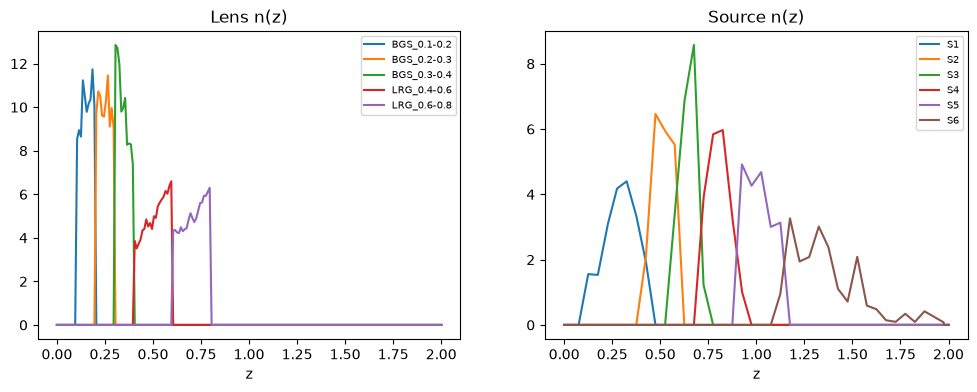

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, n in n_lenses.items():
    axes[0].plot(zs, n, label=name)
for k, n in n_sources.items():
    axes[1].plot(zs, n, label=f'S{k}')
axes[0].set_title('Lens n(z)'); axes[1].set_title('Source n(z)')
for ax in axes:
    ax.set_xlabel('z'); ax.legend(fontsize=7)
plt.show()

In [3]:
# Theorie am Startpunkt (alte Einzelkonfiguration); nach dem MCMC siehe CompareG2L.ipynb
theta0 = space.fiducial()
model0 = theory.model_vector(theta0, space)
print('chi2 / N =', round(data.chi2(model0), 1), '/', data.n)
print('Parameter:'); [print(f'  {n:28s} {v:8.3f}  [{lo:g}, {hi:g}]') for n, v, lo, hi in zip(space.names[:10], theta0, space.lo, space.hi)]

chi2 / N = 3160.2 / 440
Parameter:
  Om_c                            0.280  [0.1, 0.5]
  Om_b                            0.050  [0.03, 0.07]
  h                               0.670  [0.55, 0.85]
  sigma_8                         0.800  [0.4, 1.2]
  n_s                             0.960  [0.8, 1.2]
  BGS_0.1-0.2:alpha               1.000  [0, 1]
  BGS_0.1-0.2:sigma               0.200  [0.01, 1]
  BGS_0.1-0.2:log10_Mth          12.000  [10, 15]
  BGS_0.1-0.2:log10_Mprime       13.301  [10, 17]
  BGS_0.1-0.2:beta                1.000  [0.1, 2]


[None, None, None, None, None, None, None, None, None, None]

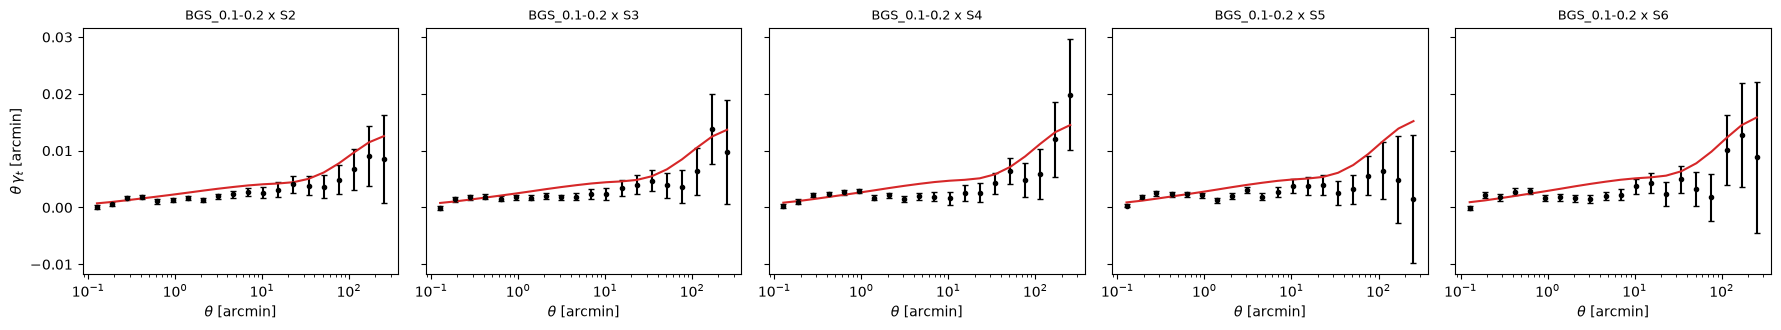

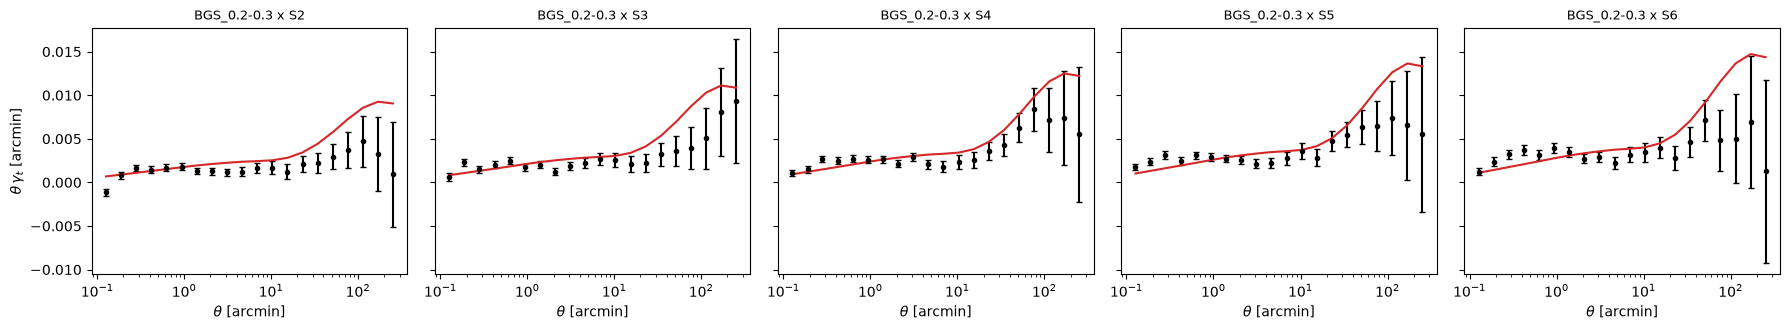

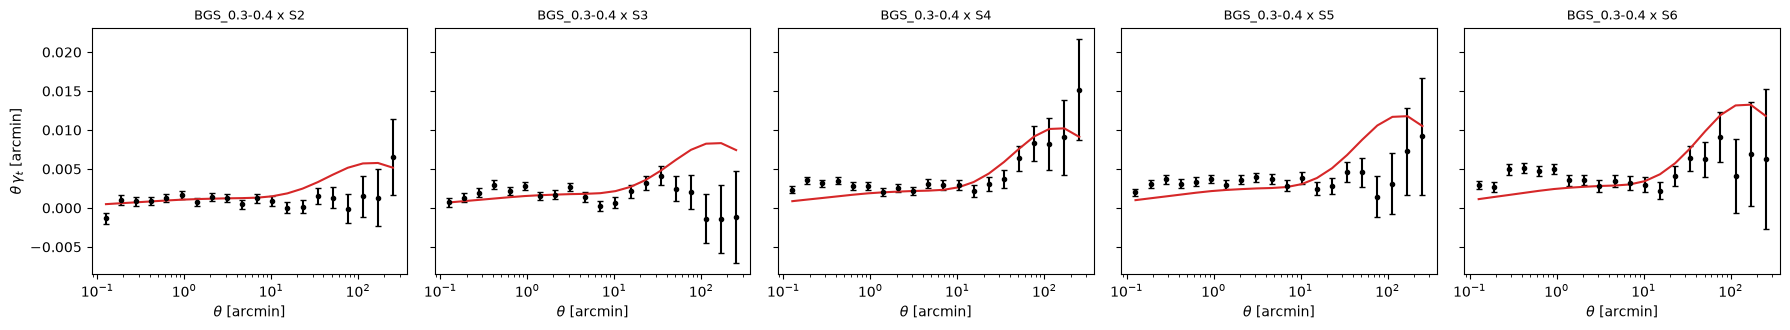

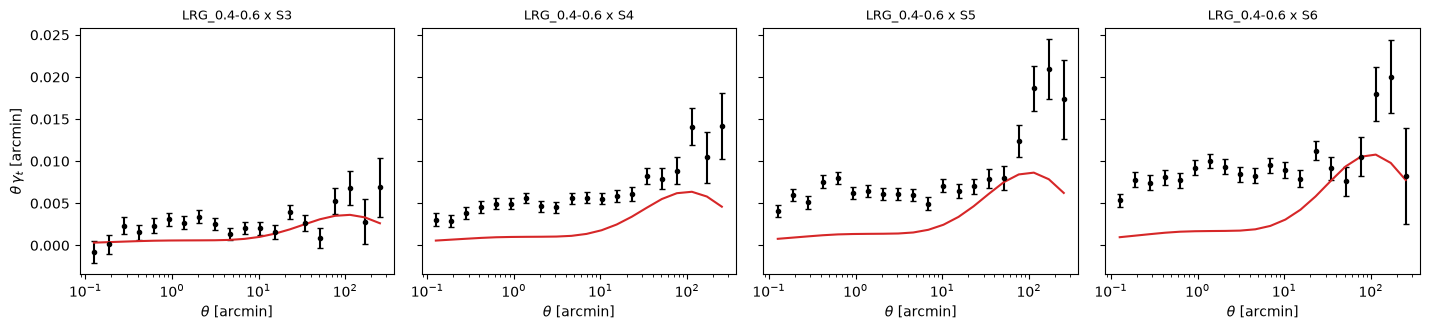

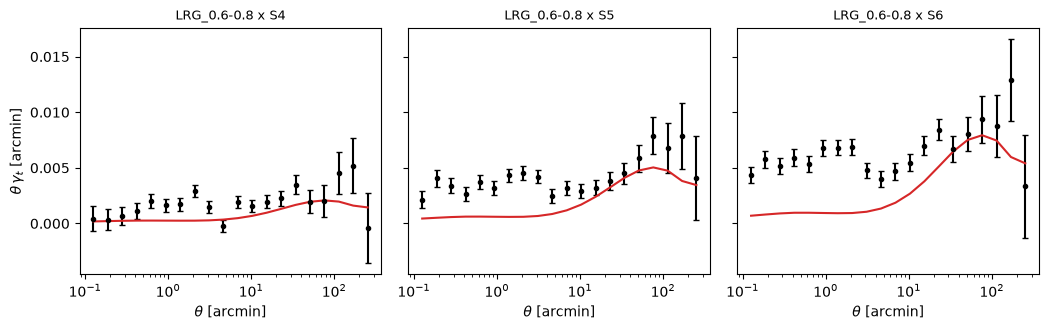

In [4]:
for lens in space.lens_names:
    items = [(i, c) for i, c in enumerate(data.combos) if c[0] == lens]
    fig, axes = plt.subplots(1, len(items), figsize=(3.6*len(items), 3.4), sharey=True, squeeze=False)
    for ax, (i, (ln, sb)) in zip(axes[0], items):
        sl = data.slices[i]
        th = data.theta[i]
        ax.errorbar(th, th*data.gt[i], yerr=th*data.sig_diag[i], fmt='o', ms=3, capsize=2, color='k')
        ax.plot(th, th*model0[sl], color='tab:red')
        ax.set_xscale('log'); ax.set_title(f'{ln} x S{sb}', fontsize=9); ax.set_xlabel(r'$\theta$ [arcmin]')
    axes[0, 0].set_ylabel(r'$\theta\,\gamma_t$ [arcmin]')
    plt.tight_layout(); plt.show()

('LRG_0.6-0.8', 4) max |NN/Halomodell - 1| = 0.02
('LRG_0.6-0.8', 5) max |NN/Halomodell - 1| = 0.02
('LRG_0.6-0.8', 6) max |NN/Halomodell - 1| = 0.02


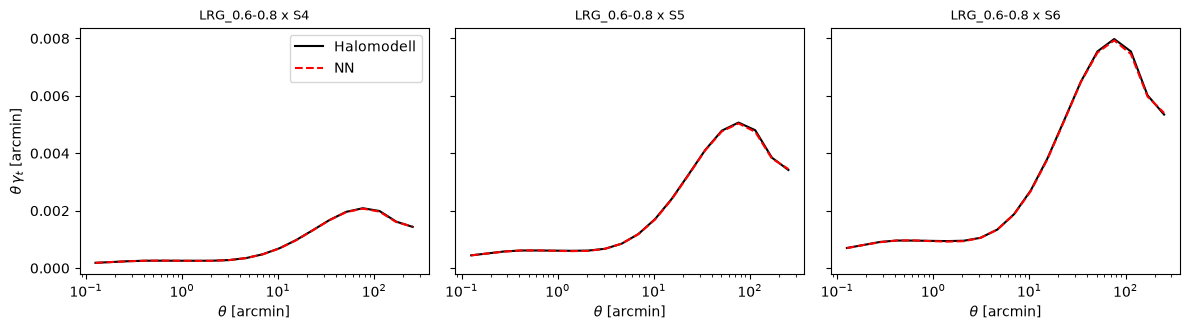

In [5]:
# Validierung gegen das volle Halomodell (langsam: ca. 15 s je Lens-Bin) bei einem Parameterpunkt
import pyccl as ccl, g3lhalo

LENS_CHECK = 'LRG_0.6-0.8'
hp_idx = space.lens_names.index(LENS_CHECK)
cv, hod_all = space.split(theta0)
hp = hod_all[hp_idx]

hod_cen, hod_sat = g3lhalo.HOD_Zheng(hp[0], 10**hp[2], hp[1], 10**hp[3], hp[4])
hm = g3lhalo.halomodel(verbose=False, cosmo=dict(zip(g.COSMO_NAMES, cv)),
                       hmfunc=ccl.halos.MassFuncSheth99(), hbfunc=ccl.halos.HaloBiasSheth01(),
                       cmfunc=ccl.halos.ConcentrationDuffy08())
hm.set_hods(hod_cen, hod_sat, A=0, epsilon=0, flens1=1, flens2=1)

combos = [c for c in data.combos if c[0] == LENS_CHECK]
th_arr = [data.theta[data.combos.index(c)] for c in combos]
th = g.G2LTheory(combos, th_arr, zs, n_lenses, n_sources, emulator=theory.emu)
bg = th.background(cv)
pm_true = np.array([hm.source_lens_ps(th.ell_c / bg['chi_l'][i], z, type=1)[2] for i, z in enumerate(th.z_l)])

hod_in = np.array([hod_all[space.lens_names.index(l)] for l in th.lens_names])
gt_true, _ = th.predict(cv, hod_in, pmats={LENS_CHECK: pm_true})
gt_nn, _ = th.predict(cv, hod_in)

fig, axes = plt.subplots(1, len(combos), figsize=(4*len(combos), 3.4), sharey=True, squeeze=False)
for ax, c, a, b, t in zip(axes[0], combos, gt_true, gt_nn, th_arr):
    ax.plot(t, t*a, 'k', label='Halomodell'); ax.plot(t, t*b, 'r--', label='NN')
    ax.set_xscale('log'); ax.set_title(f'{c[0]} x S{c[1]}', fontsize=9); ax.set_xlabel(r'$\theta$ [arcmin]')
    print(c, 'max |NN/Halomodell - 1| =', np.abs(b/a - 1).max().round(3))
axes[0, 0].legend(); axes[0, 0].set_ylabel(r'$\theta\,\gamma_t$ [arcmin]')
plt.tight_layout(); plt.show()